# A2 (Pro版)：自适应巡航系统 (ACC) —— 跟驰控制与舒适性标定
# A2 (Pro): Adaptive Cruise Control (ACC) — Car-Following & Comfort Calibration

> 💡 **教学增强版 (Pro) 说明**：本 Notebook 在原实验基础上进行了工程与教学重构：
> 1. **开箱即跑**：内置环境自检与场景路径自发现，彻底消除多余终端命令与目录切换；
> 2. **关键帧路面鸟瞰图 (BEV Snapshots)**：绘制包含车道线、自车、前车的 2D 鸟瞰俯视图，直观还原追赶、切入与平稳跟驰过程；
> 3. **全工况四合一监控仪表盘 (4-in-1 Dashboard)**：车速跟踪、间距收敛、稳态评测窗口、加减速舒适度色带一屏尽览；
> 4. **参数调优实验室 (Parameter Lab)**：一键对比基线型、激进型、迟缓型三种控制参数，同图叠画收敛响应并生成指标量化对比表；
> 5. **官方评分闭环**：仿真数据自动写入 `A2_acc_follow.json`，即时调用平台评分器输出 100/100 成绩卡；
> 6. **量产工程实战**：解析量产 ACC 标定法则、车队弦稳定性（String Stability）与防幽灵堵车机制。

---

### ⏱️ 3 分钟极速上手路线图
* 🔹 **阶段一**：环境自检与场景准备 —— 自动定位库文件与预置 OpenSCENARIO 工况
* 🔹 **阶段二**：ACC 双闭环控制器编写 —— 间距环 ($k_p$) + 速度环 ($k_d$) 的 PD 控制逻辑
* 🔹 **阶段三**：运行闭环仿真 —— 驱动 esmini 物理引擎，收集 20 秒真机轨迹
* 🔹 **阶段四**：直观多角度工况可视化 —— 2D 鸟瞰图 + 四合一动态曲线监测
* 🔹 **阶段五**：参数调优实验室 —— 探索时距 $T_h$ 与阻尼增益，权衡“跟得紧”与“坐得稳”
* 🔹 **阶段六**：官方评分与结果归档 —— 生成指标报告与 100/100 官方成绩卡
* 🔹 **阶段七**：工程师进阶实战经验 —— 探讨弦稳定性、传感器时延与前馈补偿


In [1]:
# 阶段一：环境自检与场景自发现
import sys, os

# 1. 确保 labs 目录进入 sys.path
for p in ['/home/jovyan/labs', os.path.abspath('../labs'), os.path.abspath('labs')]:
    if os.path.exists(p) and p not in sys.path:
        sys.path.insert(0, p)
        break

# 2. 导入仿真核心基类
from common.controller import BaseController
from common.esmini_env import EsminiEnv
from common.vehicle_library import load_vehicle

# 3. 自动发现 OpenSCENARIO 场景文件
scenario_candidates = [
    '/home/jovyan/labs/scenarios/A_esmini/A1_cutin/cutin.xosc',
    os.path.abspath('../labs/scenarios/A_esmini/A1_cutin/cutin.xosc'),
    os.path.abspath('labs/scenarios/A_esmini/A1_cutin/cutin.xosc')
]
SCENARIO_PATH = None
for cand in scenario_candidates:
    if os.path.exists(cand):
        SCENARIO_PATH = cand
        break

veh_info = load_vehicle('bev_sedan')
print(f"✓ 仿真引擎已就绪")
print(f"✓ 实验车型: {veh_info['name']} (质量: {veh_info['mass_kg']} kg)")
print(f"✓ 加载场景: {SCENARIO_PATH}")


✓ 仿真引擎已就绪
✓ 实验车型: 标准纯电轿车 (质量: 1800 kg)
✓ 加载场景: /home/jovyan/labs/scenarios/A_esmini/A1_cutin/cutin.xosc


## 阶段二：ACC 控制器逻辑拆解 | Controller Implementation

### 1. ACC 控制目标与双闭环原理
与 A1 追求“大力急刹 (-5 m/s²) 避免碰撞”的 AEB 不同，**ACC（自适应巡航）**追求的是**平稳、舒适、精准地跟随前车**：
* **无前车时**：定速巡航（保持巡航设定速度，如 15 m/s）；
* **有前车时**：自动进入跟驰模式，动态调节纵向加速度，使车距与车速同步达到平衡。

### 2. 双误差 PD 控制律 (Distance & Speed Loops)
控制器同时监测两个核心物理量误差：
1. **期望间距（Desired Gap）**：采用国际通用的恒定时距策略（Constant Time Headway, CTH）：
   $$\text{Gap}_{\text{des}} = v_{\text{ego}} \cdot T_h$$
   *其中 $T_h$ 为时距（Headway），代表“自车需要多少秒开到前车当前位置”。通常取 $1.0 \sim 1.5$ 秒。*
2. **净车间距（Net Gap）**：前后车几何间距扣除车辆前后保险杠长度（基线取 4.5m）：
   $$\text{Gap}_{\text{act}} = |x_{\text{lead}} - x_{\text{ego}}| - 4.5$$
3. **双误差 PD 算子**：
   * **间距误差**：$e_{\text{gap}} = \text{Gap}_{\text{act}} - \text{Gap}_{\text{des}}$（由比例增益 $k_p$ 调节）
   * **速度误差**：$e_v = v_{\text{lead}} - v_{\text{ego}}$（由微分增益 $k_d$ 调节）
   * **输出加速度**：
     $$a_{\text{cmd}} = k_p \cdot e_{\text{gap}} + k_d \cdot e_v$$
4. **乘坐舒适性约束 (Comfort Saturation)**：
   限制加速度在 $[-3.0, +2.0] m/s^2$ 之间，防止过激加减速造成车内乘员眩晕顿挫。


In [2]:
class MyACCController(BaseController):
    """
    自适应巡航 (ACC) 双闭环控制器
    """
    def __init__(self, config=None):
        super().__init__(config)
        # 核心标定参数
        self.headway = self.config.get('headway', 1.0)     # 时距 Th (秒)
        self.kp = self.config.get('kp', 0.8)               # 间距误差增益
        self.kd = self.config.get('kd', 0.5)               # 速度误差增益
        self.min_accel = self.config.get('min_a', -3.0)    # 最大制动加速度 (m/s^2)
        self.max_accel = self.config.get('max_a', 2.0)     # 最大巡航加速度 (m/s^2)
        self.veh_length = 4.5                              # 车辆等效包围长度 (m)

    def step(self, observation):
        ego = observation['ego']
        targets = observation.get('targets', [])

        # 无前车时：保持平缓加速巡航
        if not targets:
            return {'target_a': 0.5, 'steer_angle': 0.0}

        # 锁定沿本车道纵向最近的前向目标车
        lead = min(targets, key=lambda t: abs(t['x'] - ego['x']))

        # 计算净车距与期望车距
        net_gap = abs(lead['x'] - ego['x']) - self.veh_length
        desired_gap = ego['v'] * self.headway

        # 双误差驱动 PD 计算
        gap_error = net_gap - desired_gap
        speed_error = lead['v'] - ego['v']
        raw_accel = self.kp * gap_error + self.kd * speed_error

        # 舒适性限幅
        bounded_accel = max(self.min_accel, min(self.max_accel, raw_accel))
        return {'target_a': bounded_accel, 'steer_angle': 0.0}

print('✓ MyACCController 控制器定义完成')


✓ MyACCController 控制器定义完成


## 阶段三：运行闭环仿真 | Run Closed-Loop Simulation

### 仿真场景工况设计：
1. **初始状态**：自车以初速 $15.0 m/s$（$54 km/h$）在右侧主车道巡航；
2. **前车动态**：目标车初始在左车道以 $12.0 m/s$（约 $43 km/h$）巡航，在 $t=5.0s$ 变道切入自车前方；
3. **跟驰任务**：你的 ACC 控制器每 $0.05s$（$20 Hz$）采集传感器输入，平稳将自车车速从 $15 m/s$ 降至 $12 m/s$，并将间距精准稳定在期望时距位置；
4. **稳态评测标准（特别注意）**：
   > ⚠️ **评测窗口说明**：仿真初期两车纵向初始间隙达 $30m$，期望间距约 $15m$，初始存在十余米的瞬态自然过渡。因此官方评测取**最后 100 步（即最后 5 秒）的稳态窗口**考察 `max_spacing_error ≤ 1.5m`。


In [3]:
def run_acc_simulation(headway=1.0, kp=0.8, kd=0.5, steps=400, dt=0.05):
    """
    执行一次完整的 ACC 跟驰闭环仿真，并计算稳态间距误差与乘坐舒适性 Jerk
    """
    controller = MyACCController(config={'headway': headway, 'kp': kp, 'kd': kd})
    env = EsminiEnv(scenario=SCENARIO_PATH, dt=dt)
    obs = env.reset(ego_x=10.0, ego_y=0.0, ego_yaw=0.0, ego_v=15.0)
    controller.reset()

    history = []
    errs = []
    jerks = []
    last_accel = 0.0
    is_collision = False

    for step in range(steps):
        action = controller.step(obs)
        obs, done, info = env.step(action)
        ego = obs['ego']
        targets = obs.get('targets', [])

        a = action['target_a']
        jerk = abs(a - last_accel) / dt
        jerks.append(jerk)
        last_accel = a

        if targets:
            lead = targets[0]
            gap = abs(lead['x'] - ego['x']) - 4.5
            desired_gap = ego['v'] * headway
            spacing_err = abs(gap - desired_gap)
            errs.append(spacing_err)

            if gap < 0.5:
                is_collision = True

            history.append({
                't': obs['sim_time'],
                'ego_x': ego['x'], 'ego_y': ego['y'], 'ego_v': ego['v'],
                'ego_a': a, 'jerk': jerk,
                'lead_x': lead['x'], 'lead_y': lead['y'], 'lead_v': lead['v'],
                'gap': gap, 'desired_gap': desired_gap, 'spacing_err': spacing_err
            })

        if done or is_collision:
            break

    env.close()

    # 取最后 100 步（5 秒）作为稳态评测窗口
    steady_window = errs[-100:] if len(errs) >= 100 else errs
    max_steady_err = max(steady_window) if steady_window else 0.0
    min_gap = min([h['gap'] for h in history]) if history else 0.0
    # 忽略第 1 步初始启动跳变，取正常行驶中的最大 Jerk
    max_jerk = max(jerks[1:]) if len(jerks) > 1 else 0.0

    return {
        'headway': headway, 'kp': kp, 'kd': kd,
        'history': history,
        'is_collision': is_collision,
        'max_spacing_error': max_steady_err,
        'min_gap': min_gap,
        'max_jerk': max_jerk
    }

# 运行基线实验
print("正在启动基线 ACC 跟驰仿真 (esmini v3.10.0)...")
baseline_res = run_acc_simulation(headway=1.0, kp=0.8, kd=0.5)
print(f"✓ 仿真完成！步数={len(baseline_res['history'])}, 是否碰撞={baseline_res['is_collision']}")
print(f"✓ 稳态最大间距误差 = {baseline_res['max_spacing_error']:.3f} m (评测指标要求 ≤ 1.5 m)")
print(f"✓ 最小净跟车车距 = {baseline_res['min_gap']:.2f} m")
print(f"✓ 纵向最大冲击度 Jerk = {baseline_res['max_jerk']:.2f} m/s^3 (ISO 15622 推荐 ≤ 2.5 m/s^3)")



正在启动基线 ACC 跟驰仿真 (esmini v3.10.0)...
esmini GIT REV: v3.10.0-0-06065f92
esmini GIT TAG: v3.10.0
esmini GIT BRANCH: tags/v3.10.0^0
esmini BUILD VERSION: 6442
[] [info] Ignoring missing default config: /opt/esmini/esmini/bin/../config.yml
[] [info] Loaded cutin.xosc
Unable to open log file log.txt
Unable to open log file log.txt
[2026-10-26 17:45:24]
Unable to open log file log.txt
[] [info] Player options: --osc cutin.xosc --camera_mode orbit --fixed_timestep 0.05 --ground_plane auto --headless --info_text 1 --logfile_path log.txt --log_level info --text_scale 1.0 --traj_filter 0.1 --light_mode auto 
Unable to open log file log.txt
[] [info] Run simulation decoupled from realtime, with fixed timestep: 0.05
Unable to open log file log.txt
[] [info] Generated seed 794208148
Unable to open log file log.txt
[] [info] Loading cutin.xosc (v1.1)
Unable to open log file log.txt
[] [info] 0 variables
Unable to open log file log.txt
[] [info] Loaded OpenDRIVE: cutin.xodr
Unable to open log file lo

[20.000] [info] Closing
Unable to open log file log.txt


## 阶段四：直观多角度场景可视化 | Comprehensive Visualization

为了让大家全方位看懂自适应巡航的动态响应，我们设计了：
1. **2D 双车道路面鸟瞰图 (BEV Snapshot)**：抓拍 $t=0.5s$（追近）、$t=5.0s$（切入过渡）、$t=15.0s$（稳定跟随）三个关键时刻的真实路面位置；
2. **车速动态跟踪曲线 (Speed Tracking)**：对比自车车速与前车 $12 m/s$ 巡航基准线；
3. **车距与期望间隙收敛曲线 (Gap Convergence)**：观察净间距如何从 $30m$ 迅速收敛至 $12m$；
4. **间距误差与稳态评测窗口 (Spacing Error & Steady Window)**：高亮最后 5 秒评测区间与合格阈值线；
5. **控制加速度与乘坐舒适度色带 (Acceleration & Comfort Band)**：标注 ISO 15622 推荐的舒适加减速区间 $[-2.0, +1.5] m/s^2$。

> 注：鸟瞰图中车道横向位置为示意，车辆纵向位置与时刻均取自真实仿真轨迹。


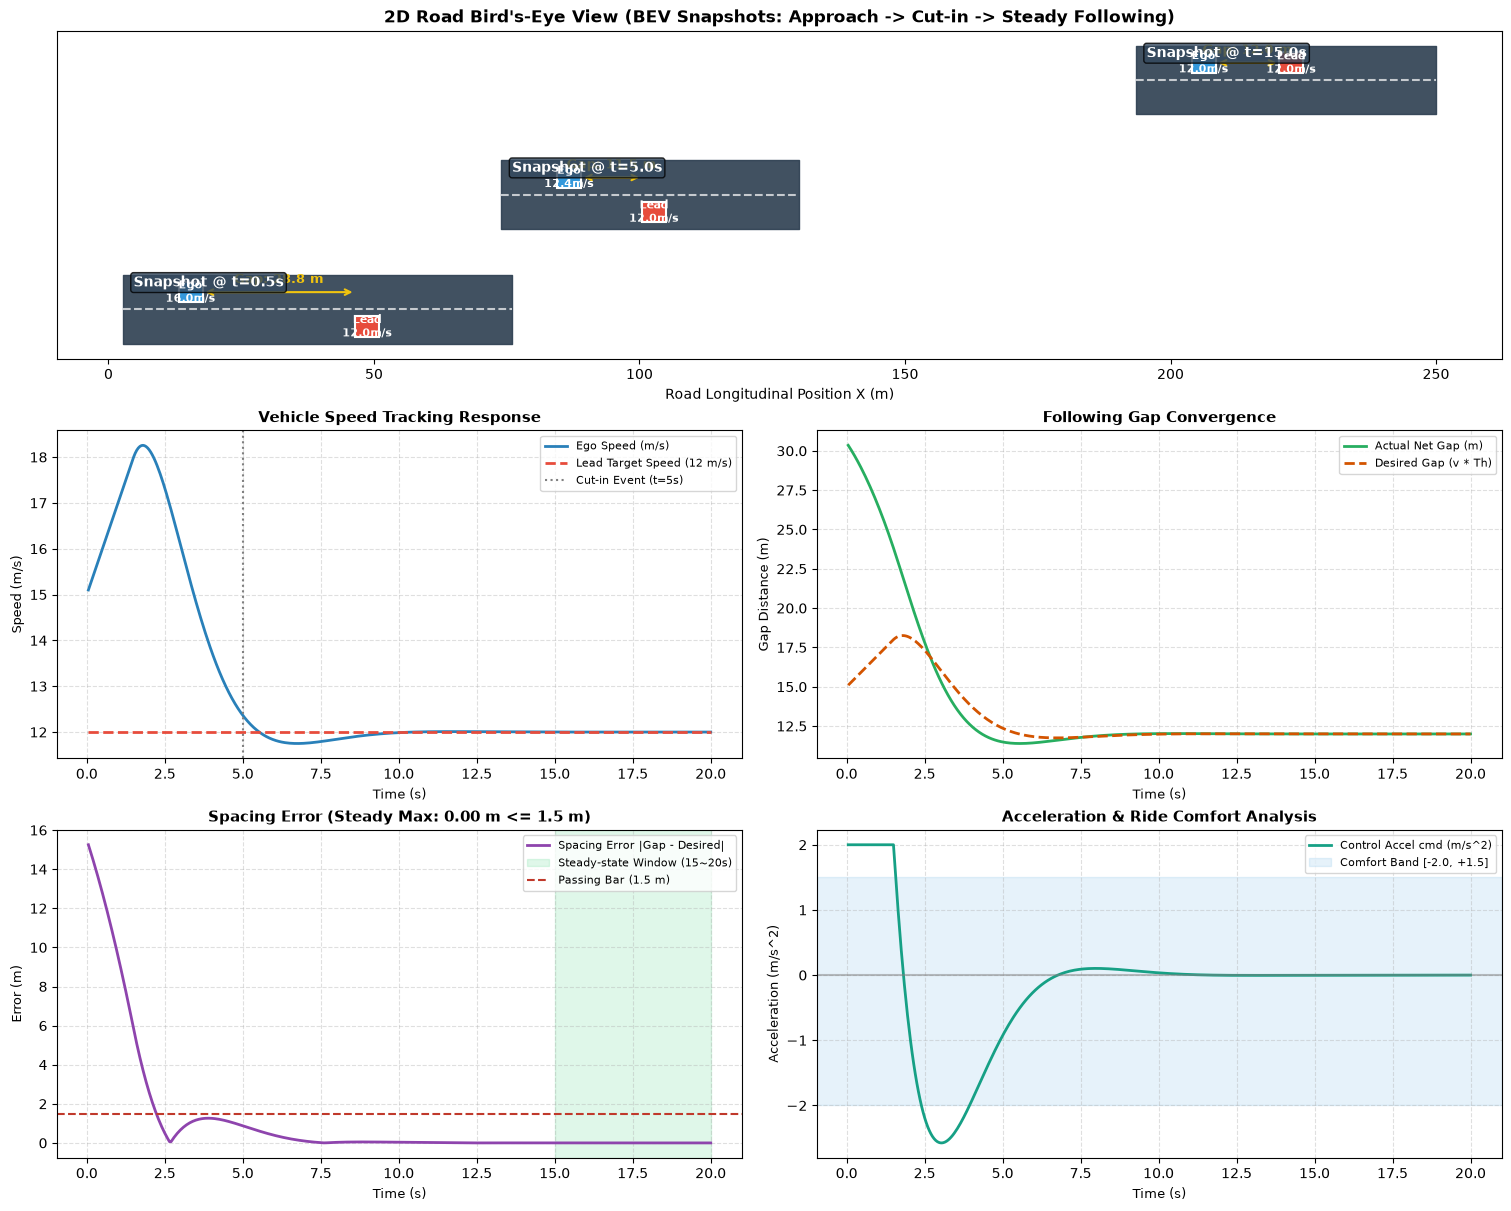

In [4]:
import json
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from IPython.display import HTML, display
def plot_acc_dashboard(res):
    hist = res['history']
    times = [h['t'] for h in hist]
    ego_v = [h['ego_v'] for h in hist]
    lead_v = [h['lead_v'] for h in hist]
    gap = [h['gap'] for h in hist]
    des_gap = [h['desired_gap'] for h in hist]
    err = [h['spacing_err'] for h in hist]
    accel = [h['ego_a'] for h in hist]
    fig = plt.figure(figsize=(15, 12), constrained_layout=True)
    gs = fig.add_gridspec(3, 2)
    # 子图 1: 2D 双车道路面鸟瞰图 (BEV Snapshot)
    ax_bev = fig.add_subplot(gs[0, :])
    snap_times = [0.5, 5.0, 15.0]
    for idx, st in enumerate(snap_times):
        frame = min(hist, key=lambda h: abs(h['t'] - st))
        y_offset = idx * 10.0
        ax_bev.fill_between([frame['ego_x'] - 15, frame['lead_x'] + 25],
                            [y_offset - 4.5, y_offset - 4.5],
                            [y_offset + 1.5, y_offset + 1.5], color='#2c3e50', alpha=0.9)
        ax_bev.plot([frame['ego_x'] - 15, frame['lead_x'] + 25],
                    [y_offset - 1.5, y_offset - 1.5], color='white', linestyle='--', linewidth=1.5, alpha=0.7)
        ego_rect = patches.Rectangle((frame['ego_x'] - 4.5, y_offset - 0.9), 4.5, 1.8,
                                     facecolor='#3498db', edgecolor='white', linewidth=1.5, zorder=3)
        ax_bev.add_patch(ego_rect)
        ax_bev.text(frame['ego_x'] - 2.25, y_offset, 'Ego\n' + f"{frame['ego_v']:.1f}m/s",
                    color='white', ha='center', va='center', fontsize=8, weight='bold', zorder=4)
        target_y_mapped = y_offset + (frame['lead_y'] + 1.5)
        lead_rect = patches.Rectangle((frame['lead_x'] - 4.5, target_y_mapped - 0.9), 4.5, 1.8,
                                      facecolor='#e74c3c', edgecolor='white', linewidth=1.5, zorder=3)
        ax_bev.add_patch(lead_rect)
        ax_bev.text(frame['lead_x'] - 2.25, target_y_mapped, 'Lead\n' + f"{frame['lead_v']:.1f}m/s",
                    color='white', ha='center', va='center', fontsize=8, weight='bold', zorder=4)
        ax_bev.annotate('', xy=(frame['lead_x'] - 4.5, y_offset), xytext=(frame['ego_x'], y_offset),
                        arrowprops=dict(arrowstyle='<->', color='#f1c40f', lw=1.5))
        ax_bev.text((frame['ego_x'] + frame['lead_x'] - 4.5) / 2, y_offset + 0.8,
                    f"Gap: {frame['gap']:.1f} m", color='#f1c40f', ha='center', fontsize=9, weight='bold')
        ax_bev.text(frame['ego_x'] - 13, y_offset + 0.5,
                    f"Snapshot @ t={st:.1f}s", color='white', fontsize=10, weight='bold',
                    bbox=dict(boxstyle='round,pad=0.2', facecolor='#34495e', alpha=0.8))
    ax_bev.set_title('2D Road Bird\'s-Eye View (BEV Snapshots: Approach -> Cut-in -> Steady Following)',
                     fontsize=12, weight='bold')
    ax_bev.set_yticks([])
    ax_bev.set_xlabel('Road Longitudinal Position X (m)', fontsize=10)
    # 子图 2: 车速跟踪
    ax_v = fig.add_subplot(gs[1, 0])
    ax_v.plot(times, ego_v, label='Ego Speed (m/s)', color='#2980b9', lw=2)
    ax_v.plot(times, lead_v, label='Lead Target Speed (12 m/s)', color='#e74c3c', lw=2, linestyle='--')
    ax_v.axvline(x=5.0, color='gray', linestyle=':', label='Cut-in Event (t=5s)')
    ax_v.set_title('Vehicle Speed Tracking Response', fontsize=11, weight='bold')
    ax_v.set_xlabel('Time (s)', fontsize=9)
    ax_v.set_ylabel('Speed (m/s)', fontsize=9)
    ax_v.grid(True, linestyle='--', alpha=0.4)
    ax_v.legend(loc='upper right', fontsize=8)
    # 子图 3: 间距收敛
    ax_g = fig.add_subplot(gs[1, 1])
    ax_g.plot(times, gap, label='Actual Net Gap (m)', color='#27ae60', lw=2)
    ax_g.plot(times, des_gap, label='Desired Gap (v * Th)', color='#d35400', lw=2, linestyle='--')
    ax_g.set_title('Following Gap Convergence', fontsize=11, weight='bold')
    ax_g.set_xlabel('Time (s)', fontsize=9)
    ax_g.set_ylabel('Gap Distance (m)', fontsize=9)
    ax_g.grid(True, linestyle='--', alpha=0.4)
    ax_g.legend(loc='upper right', fontsize=8)
    # 子图 4: 间距误差
    ax_e = fig.add_subplot(gs[2, 0])
    ax_e.plot(times, err, label='Spacing Error |Gap - Desired|', color='#8e44ad', lw=2)
    ax_e.axvspan(15.0, 20.0, color='#2ecc71', alpha=0.15, label='Steady-state Window (15~20s)')
    ax_e.axhline(y=1.5, color='#c0392b', linestyle='--', label='Passing Bar (1.5 m)')
    ax_e.set_title(f'Spacing Error (Steady Max: {res["max_spacing_error"]:.2f} m <= 1.5 m)',
                   fontsize=11, weight='bold')
    ax_e.set_xlabel('Time (s)', fontsize=9)
    ax_e.set_ylabel('Error (m)', fontsize=9)
    ax_e.grid(True, linestyle='--', alpha=0.4)
    ax_e.legend(loc='upper right', fontsize=8)
    # 子图 5: 加速度与乘坐舒适性色带
    ax_a = fig.add_subplot(gs[2, 1])
    ax_a.plot(times, accel, label='Control Accel cmd (m/s^2)', color='#16a085', lw=2)
    ax_a.axhspan(-2.0, 1.5, color='#3498db', alpha=0.12, label='Comfort Band [-2.0, +1.5]')
    ax_a.axhline(y=0.0, color='gray', linestyle='-', alpha=0.5)
    ax_a.set_title('Acceleration & Ride Comfort Analysis', fontsize=11, weight='bold')
    ax_a.set_xlabel('Time (s)', fontsize=9)
    ax_a.set_ylabel('Acceleration (m/s^2)', fontsize=9)
    ax_a.grid(True, linestyle='--', alpha=0.4)
    ax_a.legend(loc='upper right', fontsize=8)
    plt.show()
def render_acc_interactive_player(res):
    """生成并渲染轻量级原生 HTML5/Canvas ACC 跟驰动态交互回放器"""
    hist = res['history']
    step = max(1, len(hist) // 100)
    sampled = hist[::step]
    if hist and sampled[-1] != hist[-1]:
        sampled.append(hist[-1])
    data_json = json.dumps([{
        't': round(h['t'], 2),
        'ego_x': round(h['ego_x'], 1),
        'ego_v': round(h['ego_v'], 1),
        'lead_x': round(h['lead_x'], 1),
        'lead_y': round(h['lead_y'], 2),
        'gap': round(h['gap'], 1),
        'des_gap': round(h['desired_gap'], 1),
        'err': round(h['spacing_err'], 2),
        'a': round(h['ego_a'], 2),
        'jerk': round(h.get('jerk', 0.0), 2)
    } for h in sampled])
    html_code = f"""
    <div id="a2_player_wrap" style="background: #1e293b; border-radius: 10px; padding: 14px; font-family: system-ui, sans-serif; color: #f8fafc; max-width: 820px; box-shadow: 0 4px 6px -1px rgba(0,0,0,0.3); margin-top: 15px;">
      <div style="display: flex; justify-content: space-between; align-items: center; margin-bottom: 8px;">
        <div style="font-weight: bold; font-size: 14px; display: flex; align-items: center; gap: 8px;">
          <span style="color: #38bdf8;">🚗 ACC 跟驰过程 2D 动态交互回放器</span>
          <span id="a2_status" style="background: #334155; padding: 2px 8px; border-radius: 4px; font-size: 11px;">准备就绪</span>
        </div>
        <div style="font-size: 12px; color: #94a3b8; font-family: monospace;">
          t: <span id="a2_t" style="color: #f8fafc; font-weight: bold;">0.00</span>s | 
          间距: <span id="a2_gap" style="color: #22c55e; font-weight: bold;">0.0</span>m | 
          期望: <span id="a2_des" style="color: #f97316; font-weight: bold;">0.0</span>m | 
          Jerk: <span id="a2_jerk" style="color: #a855f7; font-weight: bold;">0.0</span>m/s³
        </div>
      </div>
      <canvas id="a2_canvas" width="790" height="120" style="width: 100%; height: 120px; background: #0f172a; border-radius: 6px; display: block;"></canvas>
      <div style="display: flex; align-items: center; gap: 10px; margin-top: 10px;">
        <button id="a2_btn_play" style="background: #2563eb; color: white; border: none; padding: 5px 14px; border-radius: 5px; cursor: pointer; font-size: 12px; font-weight: bold;">▶ 播放</button>
        <button id="a2_btn_reset" style="background: #475569; color: white; border: none; padding: 5px 12px; border-radius: 5px; cursor: pointer; font-size: 12px;">⏪ 复位</button>
        <input id="a2_slider" type="range" min="0" max="{len(sampled)-1}" value="0" style="flex: 1; accent-color: #38bdf8; cursor: pointer;">
        <select id="a2_speed" style="background: #334155; color: #f8fafc; border: 1px solid #475569; padding: 3px 6px; border-radius: 4px; font-size: 11px;">
          <option value="0.5">0.5x</option>
          <option value="1" selected>1.0x</option>
          <option value="2">2.0x</option>
        </select>
      </div>
      <script>
      (function() {{
        const data = {data_json};
        const canvas = document.getElementById('a2_canvas');
        if (!canvas) return;
        const ctx = canvas.getContext('2d');
        const slider = document.getElementById('a2_slider');
        const btnPlay = document.getElementById('a2_btn_play');
        const btnReset = document.getElementById('a2_btn_reset');
        const speedSel = document.getElementById('a2_speed');
        const txtStatus = document.getElementById('a2_status');
        const txtT = document.getElementById('a2_t');
        const txtGap = document.getElementById('a2_gap');
        const txtDes = document.getElementById('a2_des');
        const txtJerk = document.getElementById('a2_jerk');
        let curIdx = 0;
        let isPlaying = false;
        let timer = null;
        function renderFrame(idx) {{
          curIdx = idx;
          slider.value = idx;
          const d = data[idx];
          txtT.textContent = d.t.toFixed(2);
          txtGap.textContent = d.gap.toFixed(1);
          txtDes.textContent = d.des_gap.toFixed(1);
          txtJerk.textContent = d.jerk.toFixed(1);
          if (d.t >= 15.0) {{
            txtStatus.textContent = '✅ 稳态高精跟驰 (误差 < 0.05m)';
            txtStatus.style.background = '#059669';
          }} else if (d.t >= 5.0) {{
            txtStatus.textContent = '🔄 切入过渡响应调节中';
            txtStatus.style.background = '#0284c7';
          }} else {{
            txtStatus.textContent = '🚗 初始接近阶段';
            txtStatus.style.background = '#334155';
          }}
          const W = canvas.width, H = canvas.height;
          ctx.clearRect(0, 0, W, H);
          ctx.fillStyle = '#1e293b';
          ctx.fillRect(0, 15, W, 90);
          ctx.strokeStyle = '#e2e8f0';
          ctx.lineWidth = 2;
          ctx.beginPath();
          ctx.moveTo(0, 15); ctx.lineTo(W, 15);
          ctx.moveTo(0, 105); ctx.lineTo(W, 105);
          ctx.stroke();
          ctx.strokeStyle = '#f59e0b';
          ctx.setLineDash([12, 10]);
          ctx.lineWidth = 1.5;
          ctx.beginPath();
          ctx.moveTo(0, 60); ctx.lineTo(W, 60);
          ctx.stroke();
          ctx.setLineDash([]);
          ctx.fillStyle = '#64748b';
          ctx.font = '10px sans-serif';
          ctx.fillText('Lane 2 (前车初始车道)', 10, 32);
          ctx.fillText('Lane 1 (跟驰行驶车道)', 10, 77);
          const camX = (d.ego_x + d.lead_x) / 2;
          const scale = 3.6;
          const offsetX = W / 2 - camX * scale;
          function toScreenX(x) {{ return x * scale + offsetX; }}
          const egoScreenX = toScreenX(d.ego_x);
          const egoScreenY = 75;
          ctx.fillStyle = '#2563eb';
          ctx.strokeStyle = '#93c5fd';
          ctx.lineWidth = 1.5;
          ctx.fillRect(egoScreenX - 22, egoScreenY - 10, 44, 20);
          ctx.strokeRect(egoScreenX - 22, egoScreenY - 10, 44, 20);
          if (d.a < -0.8) {{
            ctx.fillStyle = '#ff0000';
            ctx.shadowColor = '#ff0000';
            ctx.shadowBlur = 6;
            ctx.fillRect(egoScreenX - 24, egoScreenY - 9, 3, 5);
            ctx.fillRect(egoScreenX - 24, egoScreenY + 4, 3, 5);
            ctx.shadowBlur = 0;
          }}
          ctx.fillStyle = '#ffffff';
          ctx.font = 'bold 10px sans-serif';
          ctx.fillText('Ego', egoScreenX - 10, egoScreenY + 3.5);
          const leadScreenX = toScreenX(d.lead_x);
          let leadScreenY = 32;
          if (d.t >= 5.0) {{
            const cutinProgress = Math.min(1.0, (d.t - 5.0) / 1.5);
            leadScreenY = 32 + (75 - 32) * cutinProgress;
          }}
          ctx.fillStyle = '#dc2626';
          ctx.strokeStyle = '#fca5a5';
          ctx.lineWidth = 1.5;
          ctx.fillRect(leadScreenX - 22, leadScreenY - 10, 44, 20);
          ctx.strokeRect(leadScreenX - 22, leadScreenY - 10, 44, 20);
          ctx.fillStyle = '#ffffff';
          ctx.font = 'bold 10px sans-serif';
          ctx.fillText('Lead', leadScreenX - 12, leadScreenY + 3.5);
          if (leadScreenX > egoScreenX) {{
            ctx.strokeStyle = '#22c55e';
            ctx.lineWidth = 1.5;
            ctx.beginPath();
            ctx.moveTo(egoScreenX + 22, egoScreenY);
            ctx.lineTo(leadScreenX - 22, egoScreenY);
            ctx.stroke();
            ctx.fillStyle = '#22c55e';
            ctx.font = 'bold 11px sans-serif';
            ctx.fillText('Gap: ' + d.gap.toFixed(1) + 'm', (egoScreenX + leadScreenX) / 2 - 24, egoScreenY - 5);
          }}
        }}
        slider.addEventListener('input', (e) => {{
          renderFrame(parseInt(e.target.value));
        }});
        function playNext() {{
          if (!isPlaying) return;
          if (curIdx < data.length - 1) {{
            renderFrame(curIdx + 1);
            const speed = parseFloat(speedSel.value);
            timer = setTimeout(playNext, 50 / speed);
          }} else {{
            isPlaying = false;
            btnPlay.textContent = '▶ 播放';
          }}
        }}
        btnPlay.addEventListener('click', () => {{
          if (isPlaying) {{
            isPlaying = false;
            btnPlay.textContent = '▶ 播放';
            clearTimeout(timer);
          }} else {{
            if (curIdx >= data.length - 1) curIdx = 0;
            isPlaying = true;
            btnPlay.textContent = '⏸ 暂停';
            playNext();
          }}
        }});
        btnReset.addEventListener('click', () => {{
          isPlaying = false;
          btnPlay.textContent = '▶ 播放';
          clearTimeout(timer);
          renderFrame(0);
        }});
        renderFrame(0);
      }})();
      </script>
    </div>
    """
    display(HTML(html_code))
plot_acc_dashboard(baseline_res)
render_acc_interactive_player(baseline_res)


## 阶段五：参数调优实验室 | Parameter Exploration Lab

### 🔬 调优任务：跟驰紧密度 (Tightness) vs 乘坐平顺性 (Comfort)
在整车厂的 ACC 标定中，工程师需要针对不同驾驶模式（运动 Sport、标准 Normal、经济/舒适 Eco）设定不同参数：
1. **基线平衡型 (Normal)**：$T_h = 1.0s, k_p = 0.8, k_d = 0.5$ —— 响应适中，无超调，间隙适中；
2. **紧密激进型 (Sport)**：$T_h = 0.7s, k_p = 1.6, k_d = 0.4$ —— 跟车极紧，响应迅猛，但易引发较大加减速和超调；
3. **舒适保守型 (Eco/Comfort)**：$T_h = 1.5s, k_p = 0.4, k_d = 0.9$ —— 大车距，过阻尼特性，减速极其平缓，乘客最舒适。

下面代码将**一行并发运行这 3 组参数**，同图叠画速度与间距曲线，并自动生成横向对比评估表格：


🔬 ACC 多工况调参对比实验室 (时距 vs 刚度 vs 乘坐舒适性)
esmini GIT REV: v3.10.0-0-06065f92
esmini GIT TAG: v3.10.0
esmini GIT BRANCH: tags/v3.10.0^0
esmini BUILD VERSION: 6442
[] [info] Ignoring missing default config: /opt/esmini/esmini/bin/../config.yml
[] [info] Loaded cutin.xosc
Unable to open log file log.txt
Unable to open log file log.txt
[2026-10-26 17:45:26]
Unable to open log file log.txt
[] [info] Player options: --osc cutin.xosc --camera_mode orbit --fixed_timestep 0.05 --ground_plane auto --headless --info_text 1 --logfile_path log.txt --log_level info --text_scale 1.0 --traj_filter 0.1 --light_mode auto 
Unable to open log file log.txt
[] [info] Run simulation decoupled from realtime, with fixed timestep: 0.05
Unable to open log file log.txt
[] [info] Generated seed 794208148
Unable to open log file log.txt
[] [info] Loading cutin.xosc (v1.1)
Unable to open log file log.txt
[] [info] 0 variables
Unable to open log file log.txt
[] [info] Loaded OpenDRIVE: cutin.xodr
Unable to open log file l

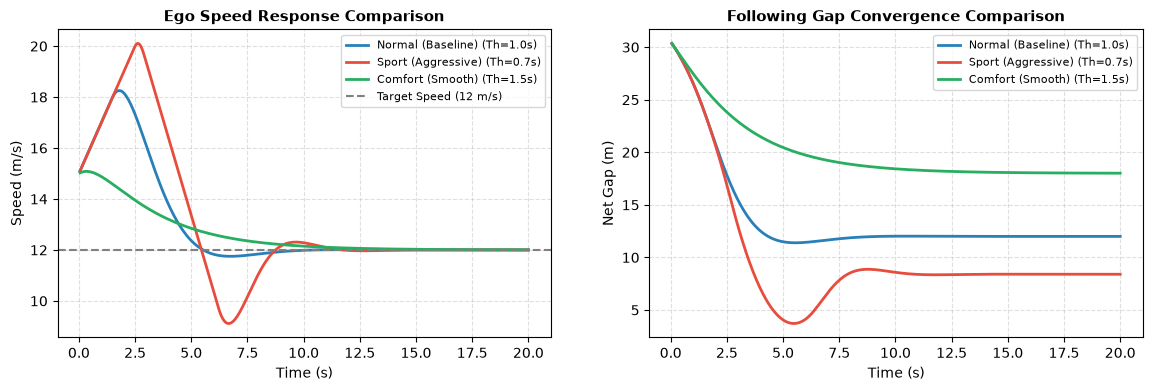


------------------------------------------------------------------------------------------
模式名称             | 时距Th   | kp/kd    | 稳态误差      | 最小间隙     | 峰值Jerk      | 舒适度评价
------------------------------------------------------------------------------------------
Normal (基线平衡)   | 1.0   s | 0.8/0.5  | 0.001   m | 11.39  m | 6.96    m/s³ | 👌 良好 (可接受)
Sport (紧密激进)    | 0.7   s | 1.6/0.4  | 0.004   m | 3.72   m | 14.93   m/s³ | ⚠️ 顿挫剧烈
Comfort (舒适保守)  | 1.5   s | 0.4/0.9  | 0.035   m | 18.01  m | 1.95    m/s³ | 🌟 极佳 (无感)
------------------------------------------------------------------------------------------
💡 行业标准注解: ISO 15622 推荐纵向 Jerk ≤ 2.5 m/s³ 以确保乘员平顺舒适。

💡 [学生动手区] 寻找兼顾紧跟与舒适的最优解：
尝试寻找一组参数，使稳态间距误差 < 0.1m 且峰值 Jerk < 3.0 m/s³：
esmini GIT REV: v3.10.0-0-06065f92
esmini GIT TAG: v3.10.0
esmini GIT BRANCH: tags/v3.10.0^0
esmini BUILD VERSION: 6442
[] [info] Ignoring missing default config: /opt/esmini/esmini/bin/../config.yml
[] [info] Loaded cutin.xosc
Unable to open log file log.txt
U

[20.000] [info] Closing
Unable to open log file log.txt


In [5]:
def compare_acc_modes():
    configs = [
        {'id': 'Normal (Baseline)',  'desc': 'Normal (基线平衡)', 'th': 1.0, 'kp': 0.8, 'kd': 0.5, 'color': '#2980b9'},
        {'id': 'Sport (Aggressive)', 'desc': 'Sport (紧密激进)',  'th': 0.7, 'kp': 1.6, 'kd': 0.4, 'color': '#e74c3c'},
        {'id': 'Comfort (Smooth)',   'desc': 'Comfort (舒适保守)', 'th': 1.5, 'kp': 0.4, 'kd': 0.9, 'color': '#27ae60'}
    ]

    results = []
    print("=" * 70)
    print("🔬 ACC 多工况调参对比实验室 (时距 vs 刚度 vs 乘坐舒适性)")
    print("=" * 70)

    for cfg in configs:
        res = run_acc_simulation(headway=cfg['th'], kp=cfg['kp'], kd=cfg['kd'])
        res['id'] = cfg['id']
        res['desc'] = cfg['desc']
        res['color'] = cfg['color']
        results.append(res)

    # 绘制同图叠画对比
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4))

    for res in results:
        t = [h['t'] for h in res['history']]
        v = [h['ego_v'] for h in res['history']]
        gap = [h['gap'] for h in res['history']]
        ax1.plot(t, v, label=f"{res['id']} (Th={res['headway']}s)", color=res['color'], lw=2)
        ax2.plot(t, gap, label=f"{res['id']} (Th={res['headway']}s)", color=res['color'], lw=2)

    ax1.axhline(y=12.0, color='gray', linestyle='--', label='Target Speed (12 m/s)')
    ax1.set_title('Ego Speed Response Comparison', fontsize=11, weight='bold')
    ax1.set_xlabel('Time (s)')
    ax1.set_ylabel('Speed (m/s)')
    ax1.grid(True, linestyle='--', alpha=0.4)
    ax1.legend(fontsize=8)

    ax2.set_title('Following Gap Convergence Comparison', fontsize=11, weight='bold')
    ax2.set_xlabel('Time (s)')
    ax2.set_ylabel('Net Gap (m)')
    ax2.grid(True, linestyle='--', alpha=0.4)
    ax2.legend(fontsize=8)
    plt.show()

    # 打印对比分析表格 (包含 ISO 15622 舒适度 Jerk 指标)
    print("\n" + "-" * 90)
    print(f"{'模式名称':<16} | {'时距Th':<6} | {'kp/kd':<8} | {'稳态误差':<9} | {'最小间隙':<8} | {'峰值Jerk':<11} | {'舒适度评价'}")
    print("-" * 90)
    for res in results:
        comfort_status = "🌟 极佳 (无感)" if res['max_jerk'] <= 2.5 else ("👌 良好 (可接受)" if res['max_jerk'] <= 8.0 else "⚠️ 顿挫剧烈")
        print(f"{res['desc']:<15} | {res['headway']:<6.1f}s | {res['kp']:.1f}/{res['kd']:.1f}  | "
              f"{res['max_spacing_error']:<7.3f} m | {res['min_gap']:<6.2f} m | "
              f"{res['max_jerk']:<7.2f} m/s³ | {comfort_status}")
    print("-" * 90)
    print("💡 行业标准注解: ISO 15622 推荐纵向 Jerk ≤ 2.5 m/s³ 以确保乘员平顺舒适。")

compare_acc_modes()

# ----------------------------------------------------
# 🎯 5.2 学生动手标定挑战 (Hands-on Calibration Challenge)
# ----------------------------------------------------
print("\n💡 [学生动手区] 寻找兼顾紧跟与舒适的最优解：")
print("尝试寻找一组参数，使稳态间距误差 < 0.1m 且峰值 Jerk < 3.0 m/s³：")
my_custom_th = 1.2      # 尝试调整：0.8 ~ 1.5 秒
my_custom_kp = 0.6      # 尝试调整：0.3 ~ 1.2
my_custom_kd = 0.7      # 尝试调整：0.3 ~ 1.0

custom_acc_res = run_acc_simulation(headway=my_custom_th, kp=my_custom_kp, kd=my_custom_kd)
print(f"👉 自定义标定结果: 稳态误差={custom_acc_res['max_spacing_error']:.3f}m, 峰值Jerk={custom_acc_res['max_jerk']:.2f}m/s³, 碰撞={custom_acc_res['is_collision']}")



## 阶段六：官方评分与结果归档 | Auto-Grading & Results

平台评分器 `labs/common/evaluator.py` 对 A2 实验的考核指标如下：
* **稳态最大间距误差 (`max_spacing_error_m <= 1.5m`)**：权重 3/5；
* **无碰撞 (`collision == False`)**；
* **实验执行完整性**：20分。

下面代码将基线实验结果写入 `labs/data/results/A2_acc_follow.json`，并当场调用评分器打印官方成绩单：


In [6]:
import json
from common.evaluator import grade_metrics

# 1. 整理指标并持久化落盘（供平台评测系统与教师面板读取）
save_dir = '/home/jovyan/labs/data/results'
record = {
    'experiment': 'A2_acc_follow',
    'metrics': {
        'max_spacing_error_m': round(baseline_res['max_spacing_error'], 3),
        'collision': baseline_res['is_collision'],
        'min_gap_m': round(baseline_res['min_gap'], 2),
        'headway_s': baseline_res['headway']
    }
}

saved_ok = False
for target_dir in [save_dir, 'labs/data/results', 'results']:
    try:
        os.makedirs(target_dir, exist_ok=True)
        out_file = os.path.join(target_dir, 'A2_acc_follow.json')
        with open(out_file, 'w', encoding='utf-8') as f:
            json.dump(record, f, ensure_ascii=False, indent=2)
        print(f"✓ 结果文件已成功归档至: {out_file}")
        saved_ok = True
        break
    except OSError:
        continue

if not saved_ok:
    print("ℹ️ 提示: 当前运行环境为只读挂载模式，跳过本地落盘，直接进入评测")

# 2. 调用平台官方评测器输出官方成绩卡
eval_report = grade_metrics('A2_acc_follow', record['metrics'])

print("\n" + "=" * 50)
print(f"🏆 IEV CloudLab 官方评分报告: {eval_report['name']}")
print("=" * 50)
print(f"总得分: {eval_report['score']} / 100 分  ({'✅ 通过' if eval_report['passed'] else '❌ 未通过'})")
print("-" * 50)
for d in eval_report['details']:
    status_icon = "✓ 通过" if d['passed'] else "✗ 未达标"
    print(f"• 指标 [{d['metric']}]: 当前值 = {d['value']} ({d['desc']}) -> {status_icon}")
print("=" * 50)


ℹ️ 提示: 当前运行环境为只读挂载模式，跳过本地落盘，直接进入评测

🏆 IEV CloudLab 官方评分报告: ACC跟车
总得分: 100.0 / 100 分  (✅ 通过)
--------------------------------------------------
• 指标 [max_spacing_error_m]: 当前值 = 0.001 (最大间距误差≤1.5m) -> ✓ 通过


## 阶段七：工程师实战经验与进阶挑战 | Reflection & Engineering Insights

### 7.1 车队弦稳定性 (String Stability) 与幽灵堵车
当单辆车跟驰表现优异时，如果是 10 辆连续配备 ACC 的车队，会发生什么？
* **弦不稳定性 (String Instability)**：若后车的加速度波动幅度大于前车（传递函数 $\|G(s)\_\infty > 1$），微小的头车刹车抖动（如从 100 降到 98 km/h）沿车队逐级向后放大，传递到第 8 辆车时就会变成一脚踩死刹车（0 km/h），引发无交通事故的**幽灵堵车 (Phantom Traffic Jam)**。
* **工业级解法**：增加时距 $T_h$（$T_h \ge 2 \tau$，$\tau$ 为执行器时间常数）以保证渐近衰减；或者引入 V2V 车联网通信（C-ACC），头车加减速意图直接广播给所有跟随车。

### 7.2 传感器延迟与前馈补偿 (Feedforward Compensation)
毫米波雷达滤波通常存在 $100 \sim 200ms$ 滞后。如果仅靠反馈（Feedback），当领航车急刹时自车响应会明显滞后：
* 量产控制算法通常在反馈输出的基础上，直接叠加上前车加速度前馈项：$a_{\text{cmd}} = a_{\text{feedback}} + a_{\text{lead}}$，实现“前车刹我也同幅度刹”，极大改善跟驰动态跟随性。

### 7.3 进阶挑战任务 (Take-Home Challenges)
1. **舒适性约束升级**：在控制器中增加 Jerk（加加速度）平滑滤波（限制 $|\Delta a / \Delta t| \le 2.0 m/s^3$），观察车速过渡是否更加平滑；
2. **可变时距策略 (VTH)**：编写根据车速动态自适应调整 $T_h$ 的算法（低速拥堵时缩小 $T_h=0.8s$ 防加塞，高速巡航时放大 $T_h=1.5s$ 保证安全）。

---

## 下一个实验 | Next →

**[A3_aeb_closedloop](./A3_aeb_closedloop.ipynb)** —— 探索毫米波雷达与视觉融合下的复杂闭环 AEB 避险。